In [1]:
!rm -rf clone && git clone https://github.com/ferit-osirv/lab4 clone && cp -a clone/. .

Cloning into 'clone'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 19 (delta 1), reused 3 (delta 0), pack-reused 12 (from 1)
Receiving objects: 100% (19/19), 3.68 MiB | 14.23 MiB/s, done.
Resolving deltas: 100% (1/1), done.


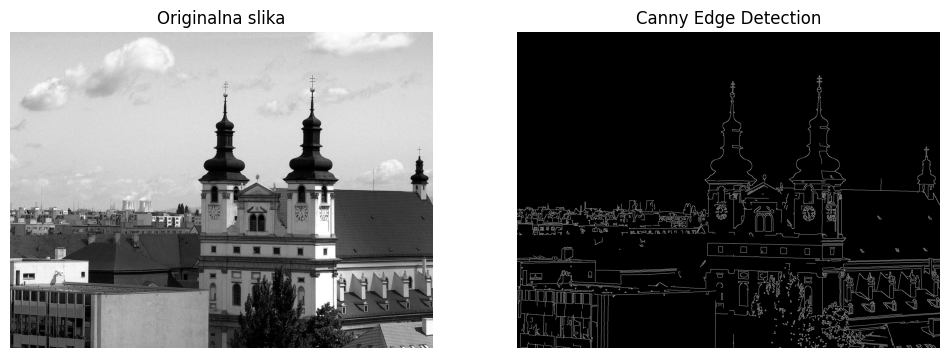

In [5]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math


image = cv.imread('./images/building_1.jpg', cv.IMREAD_GRAYSCALE)


blurred = cv.GaussianBlur(image, (5, 5), 0)


lower_threshold = 100
upper_threshold = 200

edges = cv.Canny(blurred, lower_threshold, upper_threshold)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.show()

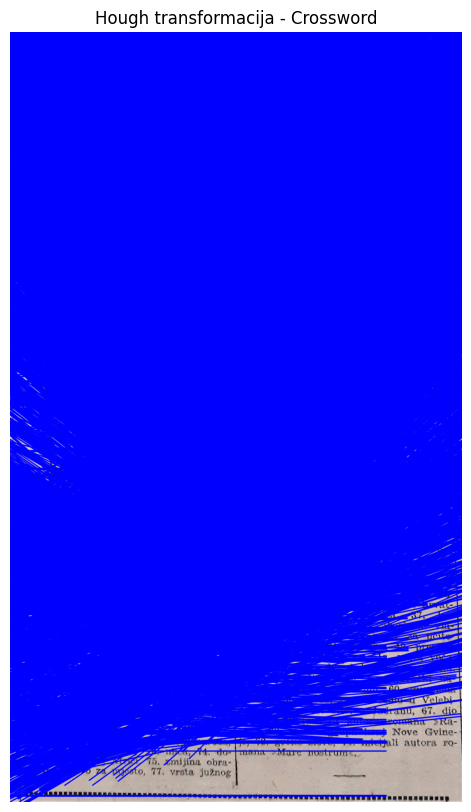

In [6]:
def draw_lines(img, lines):
    a, b, c = lines.shape

    for i in range(a):
        rho = lines[i][0][0]
        theta = lines[i][0][1]

        a = math.cos(theta)
        b = math.sin(theta)

        x0, y0 = a * rho, b * rho

        pt1 = (
            int(x0 + 1000 * (-b)),
            int(y0 + 1000 * (a))
        )

        pt2 = (
            int(x0 - 1000 * (-b)),
            int(y0 - 1000 * (a))
        )

        cv.line(img, pt1, pt2, (255, 0, 0), 2, cv.LINE_AA)

    return img



image = cv.imread('./images/crossword.jpg')


gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)


blurred = cv.GaussianBlur(gray, (5, 5), 0)

edges = cv.Canny(blurred, 100, 200)


lines = cv.HoughLines(
    edges,
    1,
    math.pi / 90,
    200,
    np.array([]),
    0,
    0
)


result = draw_lines(image.copy(), lines)


result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)


plt.figure(figsize=(10, 10))
plt.imshow(result_rgb)
plt.title('Hough transformacija - Crossword')
plt.axis('off')
plt.show()

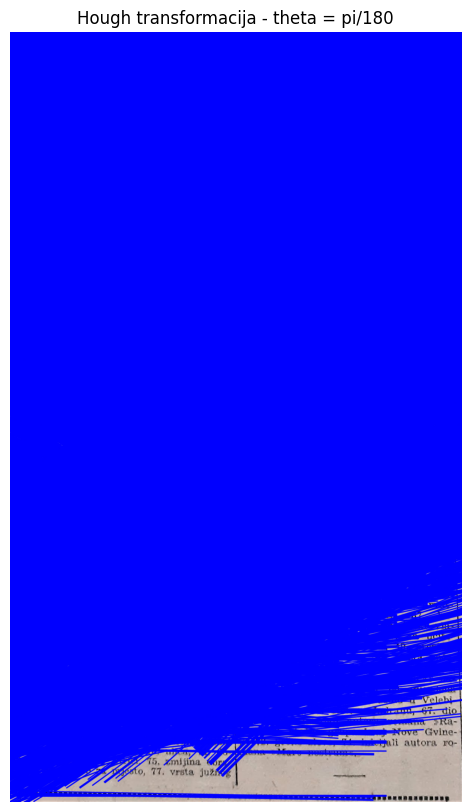

In [7]:
def draw_lines(img, lines):
    a, b, c = lines.shape

    for i in range(a):
        rho = lines[i][0][0]
        theta = lines[i][0][1]

        a = math.cos(theta)
        b = math.sin(theta)

        x0, y0 = a * rho, b * rho

        pt1 = (
            int(x0 + 1000 * (-b)),
            int(y0 + 1000 * (a))
        )

        pt2 = (
            int(x0 - 1000 * (-b)),
            int(y0 - 1000 * (a))
        )

        cv.line(img, pt1, pt2, (255, 0, 0), 2, cv.LINE_AA)

    return img



image = cv.imread('./images/crossword.jpg')


gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)


blurred = cv.GaussianBlur(gray, (5, 5), 0)


edges = cv.Canny(blurred, 100, 200)


lines = cv.HoughLines(
    edges,
    1,
    math.pi / 180,
    200,
    np.array([]),
    0,
    0
)


result = draw_lines(image.copy(), lines)


result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)


plt.figure(figsize=(10, 10))
plt.imshow(result_rgb)
plt.title('Hough transformacija - theta = pi/180')
plt.axis('off')
plt.show()

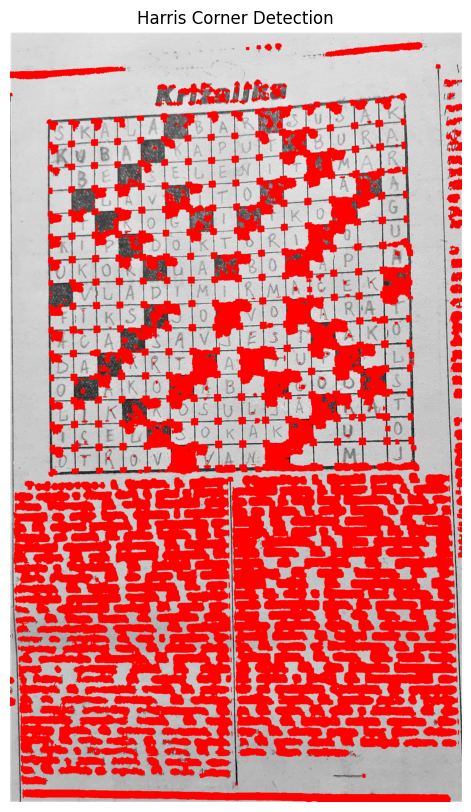

In [8]:
img = cv.imread('./images/crossword.jpg', cv.IMREAD_GRAYSCALE)


corners = cv.cornerHarris(img, 15, 3, 0.05)


threshold = 0.0001


result = cv.cvtColor(img, cv.COLOR_GRAY2BGR)


result[corners > threshold] = [0, 0, 255]


result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)


plt.figure(figsize=(10, 10))
plt.imshow(result_rgb)
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()